# Homework 2  

Building and Comparing MNIST Models

This notebook explains data preparation, the initial and optimized CNNs, pretrained SqueezeNet 1.1, int8 conversion, and evaluation.


## 1. Experiment objective


- **MNIST:** 54,000 training images and 6,000 validation images.
- **Touchscreen drawings:** one labeled image per digit, used only for evaluation. They are not used for training or quantization calibration.

This separation prevents evaluating the model on examples it has already seen during training. The custom evaluation set is small (10 images)

## 2. Preparing the touchscreen images

The original captures are in sd_data/

In [11]:
from pathlib import Path
import sys

candidates = [Path.cwd(), Path.cwd() / "Home assignment 2", Path.cwd().parent / "Home assignment 2"]
HW2_DIR = next((p.resolve() for p in candidates if (p / "tools" / "experiments.py").is_file()), None)
if HW2_DIR is None:
    raise FileNotFoundError("Could not find Home assignment 2/tools/experiments.py")
if str(HW2_DIR) not in sys.path:
    sys.path.insert(0, str(HW2_DIR))

from tools.experiments import (
    custom_cnn,
    load_mnist,
    load_own_data,
    run,
    tflite_bytes,
    tflite_predict,
)

print(f"Homework 2 folder: {HW2_DIR}")

Homework 2 folder: /Users/jordane.fernandezruiz/ias0360-lab-excercises-2026/Home assignment 2


## 3. Loading, normalizing, and splitting MNIST

`load_mnist()` is the original script function. It scales pixel values from 0–255 to [0, 1], 
adds the channel dimension, and reserves the last 6,000 images for validation.

 The expected shapes are (54000, 28, 28, 1) for training and (6000, 28, 28, 1) for validation.

In [2]:
x_train, y_train, x_val, y_val = load_mnist()
print("Training:", x_train.shape, y_train.shape, x_train.dtype)
print("Validation:", x_val.shape, y_val.shape, x_val.dtype)
print("Pixel range:", float(x_train.min()), "to", float(x_train.max()))

Training: (54000, 28, 28, 1) (54000,) float32
Validation: (6000, 28, 28, 1) (6000,) float32
Pixel range: 0.0 to 1.0


## 4. Custom data: checking the labels

`load_own_data()` loads images from `own_data/`

In [12]:
OWN_DIR = HW2_DIR / "own_data"
own = load_own_data(str(OWN_DIR))
if own is None:
    raise FileNotFoundError(f"No labeled images found in {OWN_DIR}")
x_own, y_own, own_names = own
# if len(y_own) != 10 or sorted(y_own.tolist()) != list(range(10)):
#     raise ValueError("Expected exactly one labeled custom image for each digit 0–9")
print("Custom data:", x_own.shape, y_own.shape)
print("Files:", own_names)

Custom data: (10, 28, 28, 1) (10,)
Files: ['0_lcd_sd_card_example_0.png', '1_lcd_sd_card_example_1.png', '2_lcd_sd_card_example_2.png', '3_lcd_sd_card_example_3.png', '4_lcd_sd_card_example_4.png', '5_lcd_sd_card_example_5.png', '6_lcd_sd_card_example_6.png', '7_lcd_sd_card_example_7.png', '8_lcd_sd_card_example_8.png', '9_lcd_digit9.png']


Label 0: 0_lcd_sd_card_example_0.png


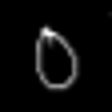

Label 1: 1_lcd_sd_card_example_1.png


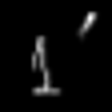

Label 2: 2_lcd_sd_card_example_2.png


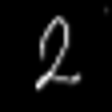

Label 3: 3_lcd_sd_card_example_3.png


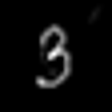

Label 4: 4_lcd_sd_card_example_4.png


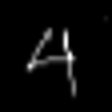

Label 5: 5_lcd_sd_card_example_5.png


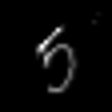

Label 6: 6_lcd_sd_card_example_6.png


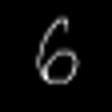

Label 7: 7_lcd_sd_card_example_7.png


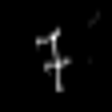

Label 8: 8_lcd_sd_card_example_8.png


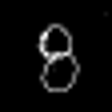

Label 9: 9_lcd_digit9.png


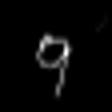

In [4]:
# Preview the 10 examples without requiring an additional plotting library.
from IPython.display import display
from PIL import Image

for name, label, image in zip(own_names, y_own, x_own):
    print(f"Label {label}: {name}")
    display(Image.fromarray((image.squeeze() * 255).astype("uint8")).resize((112, 112)))

## 5. Compared architectures


1. **Initial CNN:** 16/32 filters and a 64-unit dense layer.
2. **Optimized CNN:** 8/16 filters and a 32-unit dense layer.
3. **SqueezeNet 1.1:** pretrained on ImageNet and fine-tuned on MNIST.

The CNNs accept `(28, 28, 1)` images. SqueezeNet inputs are resized to 64×64, repeated into three channels, and normalized. Section 14 loads its saved model.

In [ ]:
builders = {
    "Initial CNN 16/32/d64": lambda: custom_cnn(),
    "Optimized CNN 8/16/d32": lambda: custom_cnn((8, 16), 32),
}

for name, build_model in builders.items():
    model = build_model()
    print(f"\n--- {name} | parameters: {model.count_params():,} ---")
    model.summary()

## 6. Training Basis and Others

The CNNs use sparse categorical cross-entropy. The reference configuration for all three models is Adam, learning rate 0.001, 100 epochs, and batch size 128. SqueezeNet is fine-tuned separately in PyTorch.

The original `run()` function handles CNN compilation, training, TFLite conversion, and evaluation. Set the flag below to retrain the two CNNs and write `results/notebook_results.csv`; this overwrites that file. SqueezeNet's saved results are shown below without retraining.

In [ ]:
import csv
import tensorflow as tf

RUN_FULL_TRAINING = False  # Set to True to retrain the two CNNs.

if RUN_FULL_TRAINING:
    tf.keras.utils.set_random_seed(0)
    notebook_results = []
    notebook_predictions = []
    plan = [
        ("Initial CNN 16/32/d64", lambda: custom_cnn()),
        ("Optimized CNN 8/16/d32", lambda: custom_cnn((8, 16), 32)),
    ]
    for name, build_model in plan:
        tf.keras.utils.set_random_seed(0)
        run(
            name, "Architecture comparison + int8", build_model(), "adam",
            1e-3, 100, 128, (x_train, y_train, x_val, y_val), own,
            True, notebook_results, notebook_predictions,
        )
    salida = HW2_DIR / "results" / "notebook_results.csv"
    salida.parent.mkdir(parents=True, exist_ok=True)
    with salida.open("w", newline="", encoding="utf-8") as archivo:
        writer = csv.DictWriter(archivo, fieldnames=list(notebook_results[0]))
        writer.writeheader()
        writer.writerows(notebook_results)
    print(f"Results saved to: {salida}")
else:
    print("Training skipped. Set RUN_FULL_TRAINING to True to run it.")

## 7. TensorFlow Lite conversion and int8 quantization

In `run()`, the trained model is converted with `tflite_bytes(model, calib, quantize=True)`. The function enables size optimizations, requests int8 operations, and sets int8 inputs and outputs. The representative dataset for calibrating ranges uses the first 200 **MNIST training images**. It does not use custom drawings, preserving an independent evaluation.

Inference then uses `tflite_predict()`: for int8 inputs and outputs, it applies the scale and zero-point parameters, then computes the predicted class, confidence, and average time per image. `run()` compares predictions with the MNIST validation labels and the labels of the 10 custom examples.

## 8. Optional int8 format demonstration without training

The next cell demonstrates the original conversion and inference functions with a newly constructed, **untrained** CNN. It only illustrates the format and output shape; its predictions are not valid experiment results. To generate meaningful metrics, run the previous cell with full training enabled.

In [7]:
if RUN_FULL_TRAINING:
    print("Full training already generates and evaluates the quantized models.")
else:
    demo_model = custom_cnn()
    demo_model_bytes = tflite_bytes(demo_model, x_train, quantize=True)
    demo_prediction, demo_confidence, demo_ms = tflite_predict(demo_model_bytes, x_own[:1])
    print(f"int8 artifact size: {len(demo_model_bytes):,} bytes")
    print(f"Demo prediction (untrained model): {demo_prediction[0]}")
    print(f"Measured time: {demo_ms:.3f} ms/image")
    print("Do not interpret this prediction as a homework result.")

INFO:tensorflow:Assets written to: /var/folders/94/9xylj9lj17vdym1pp_696nt00000gn/T/tmp3gccrq7k/assets


INFO:tensorflow:Assets written to: /var/folders/94/9xylj9lj17vdym1pp_696nt00000gn/T/tmp3gccrq7k/assets


Saved artifact at '/var/folders/94/9xylj9lj17vdym1pp_696nt00000gn/T/tmp3gccrq7k'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor_89')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  13189631056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13189630672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13189629520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13189629712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13189631248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13189629328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13189631632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13189631440: TensorSpec(shape=(), dtype=tf.resource, name=None)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1794746106.765655 1616954 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.


int8 artifact size: 62,992 bytes
Demo prediction (untrained model): 2
Measured time: 1.267 ms/image
Do not interpret this prediction as a homework result.


W0000 00:00:1794746106.765963 1616954 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
2026-11-15 14:35:06.767064: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /var/folders/94/9xylj9lj17vdym1pp_696nt00000gn/T/tmp3gccrq7k
2026-11-15 14:35:06.767426: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-11-15 14:35:06.767432: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/94/9xylj9lj17vdym1pp_696nt00000gn/T/tmp3gccrq7k
I0000 00:00:1794746106.770137 1616954 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
2026-11-15 14:35:06.770589: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-11-15 14:35:06.803791: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: /var/folders/94/9xylj9lj17vdym1pp_696nt00000gn/T/tmp3gccrq7k
2026-11-15 14:35:06.809481: I tensorflow/cc/s

## 9. Hyperparameter sweep

The scripts compare training configurations across the two CNNs and SqueezeNet, using the 100-epoch Adam result as the reference. Additional trials are:

- SGD, learning rate 0.05 for the CNNs and 0.005 for SqueezeNet, 10 epochs.
- Adam, learning rate 0.001, 10 epochs.
- Adam, learning rate 0.001, 50 epochs.

All trials use a batch size of 128 and the same data and quantization setup.

## 10. Existing reference results

The saved reference results and selections include all three models. Values may differ when retraining; model sizes are for quantized TFLite files.

In [ ]:
import pandas as pd

resultados_path = HW2_DIR / "results" / "pretrained_finetuned_trials" / "report_data" / "results.csv"
if resultados_path.is_file():
    display(pd.read_csv(resultados_path))
else:
    raise FileNotFoundError(f"{resultados_path} not found; run tools/prepare_pretrained_report.py.")

resumen_path = resultados_path.parent / "optimization_summary.csv"
if resumen_path.is_file():
    print("Training configuration summary:")
    display(pd.read_csv(resumen_path))
else:
    raise FileNotFoundError(f"{resumen_path} not found; run tools/prepare_pretrained_report.py.")

### Interpretation

The initial CNN achieved 99.25% MNIST validation accuracy and 90% on the drawings, with a 64,488-byte int8 file. The optimized CNN reached 98.53% and 50%, with a 20,688-byte file. SqueezeNet achieved 99.47% and 90%, with an 823,464-byte file.

The initial CNN offers the best balance of accuracy and size. The optimized CNN is smallest, while SqueezeNet has the highest validation accuracy. Ten drawings are too few to establish generalization.

##  Create the TFLite model

We chose the smallest CNN: 8 and 16 filters, followed by 32 dense units. The export is a newly trained model with the same settings, not the original saved weights.

The next cell shows the main steps from [`export_pico_model.py`](tools/export_pico_model.py): train on MNIST, convert to int8, and save the TFLite model and a C++ array for the Pico. The conversion uses 200 MNIST training images for calibration, not our drawings.

First run the earlier import and data-loading cells. Set `CREATE_PICO_MODEL = True` to train for 100 epochs. **This overwrites** `models/optimized_cnn.tflite` and `models/optimized_cnn_model_data.cpp`.

The existing export is 19,640 bytes. It achieved 98.53% on MNIST validation and 50% on only ten custom drawings.

In [10]:
import tensorflow as tf
from tools.export_pico_model import write_cpp_array

CREATE_PICO_MODEL = False  # Set to True to train and overwrite the exported files.
if CREATE_PICO_MODEL:
    tf.keras.utils.set_random_seed(0)
    pico_model = custom_cnn((8, 16), 32)
    pico_model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    pico_model.fit(x_train, y_train, epochs=100, batch_size=128,
                   validation_data=(x_val, y_val), verbose=2)

    pico_bytes = tflite_bytes(pico_model, x_train, quantize=True, fixed_batch=True)
    model_dir = HW2_DIR / "models"
    model_dir.mkdir(parents=True, exist_ok=True)
    (model_dir / "optimized_cnn.tflite").write_bytes(pico_bytes)
    write_cpp_array(pico_bytes, model_dir / "optimized_cnn_model_data.cpp")
    val_predictions, _, _ = tflite_predict(pico_bytes, x_val)
    print(f"Validation accuracy: {(val_predictions == y_val).mean():.2%}")
    print(f"Saved TFLite model: {len(pico_bytes):,} bytes")
else:
    print("Training skipped; using the existing export below.")

Training skipped; using the existing export below.


Test the exported model on the ten custom images without retraining:

In [9]:
model_bytes = (HW2_DIR / "models" / "optimized_cnn.tflite").read_bytes()
predictions, _, _ = tflite_predict(model_bytes, x_own)

print(f"Model size: {len(model_bytes):,} bytes")
for actual, predicted in zip(y_own, predictions):
    print(f"Actual: {actual}, predicted: {predicted}")
print(f"Custom accuracy: {(predictions == y_own).mean():.1%}")

Model size: 19,640 bytes
Actual: 0, predicted: 7
Actual: 1, predicted: 5
Actual: 2, predicted: 1
Actual: 3, predicted: 3
Actual: 4, predicted: 4
Actual: 5, predicted: 5
Actual: 6, predicted: 6
Actual: 7, predicted: 1
Actual: 8, predicted: 9
Actual: 9, predicted: 9
Custom accuracy: 50.0%


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 13. Load the model on the Pico


```bash
./flash.sh "Home assignment 1/build-homework-2-docker/digit_recognition.uf2"
```


## 14. SqueezeNet 1.1

We use torchvision's **SqueezeNet 1.1**, initialized with ImageNet weights and a new 10-class classifier. All layers were fine-tuned on 54,000 MNIST images; the remaining 6,000 were used for validation.

Images are resized from 28×28 grayscale to 64×64 RGB and normalized for ImageNet. Each model is converted to int8 TFLite and tested on the validation images and ten drawings. The SGD trial uses learning rate 0.005 because 0.05 produced non-finite weights.

The next cell loads the saved **100-epoch Adam weights** and shows the model; it does not retrain. PyTorch and torchvision are required. The initial ImageNet weights may be downloaded if they are not cached.

In [14]:
import torch
from tools.pretrained_comparison import build_model

squeezenet = build_model("SqueezeNet 1.1")
for parameter in squeezenet.parameters():
    parameter.requires_grad_(True)
weights = HW2_DIR / "results" / "pretrained_finetuned_trials" / "squeezenet_reference.pth"
squeezenet.load_state_dict(torch.load(weights, map_location="cpu", weights_only=True))
squeezenet.eval()
print(squeezenet)
print(f"Parameters: {sum(p.numel() for p in squeezenet.parameters()):,}")

SqueezeNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=True)
    (3): Fire(
      (squeeze): Conv2d(64, 16, kernel_size=(1, 1), stride=(1, 1))
      (squeeze_activation): ReLU(inplace=True)
      (expand1x1): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1))
      (expand1x1_activation): ReLU(inplace=True)
      (expand3x3): Conv2d(16, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (expand3x3_activation): ReLU(inplace=True)
    )
    (4): Fire(
      (squeeze): Conv2d(128, 16, kernel_size=(1, 1), stride=(1, 1))
      (squeeze_activation): ReLU(inplace=True)
      (expand1x1): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1))
      (expand1x1_activation): ReLU(inplace=True)
      (expand3x3): Conv2d(16, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (expand3x3_activation): ReLU(inplace=True)
    )
    (5): MaxPool2d

In [15]:
import pandas as pd

results = HW2_DIR / "results" / "pretrained_finetuned_trials" / "squeezenet_trials.csv"
display(pd.read_csv(results)[["optimizer", "learning_rate", "epochs", "batch_size",
                              "parameters", "tflite_model_bytes", "own_data_avg_inference_ms",
                              "validation_accuracy", "own_data_accuracy"]])

,optimizer,learning_rate,epochs,batch_size,parameters,tflite_model_bytes,own_data_avg_inference_ms,validation_accuracy,own_data_accuracy
0,adam,0.001,100,128,727626,823464,0.255,99.47%,90.0%
1,sgd,0.005,10,128,727626,823464,0.217,99.22%,100.0%
2,adam,0.001,10,128,727626,823464,0.238,98.85%,90.0%
3,adam,0.001,50,128,727626,823464,0.240,99.35%,80.0%
